# Food Delivery Time Prediction
Alur lengkap: EDA → split → cleaning → feature engineering → modeling → evaluasi (tanpa Pipeline).
Jalankan cell secara berurutan dari atas.

## 1. Import & load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

file_id = '1oi1rd1LF3rZ--MxsOXVJ9Vhae39gDlsn'
url = f'https://drive.google.com/uc?export=download&id={file_id}'
df = pd.read_csv(url, sep=';')
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [20]:
df.duplicated().sum()

np.int64(0)

In [23]:
df.duplicated(subset=['Order_ID', 'Weather', 'Time_of_Day']).sum()

np.int64(0)

## Problem Statement

**Masalah.** Estimasi waktu pengantaran yang hanya memakai rata-rata kurang akurat.
Hal ini membuat pelanggan kecewa dan menyulitkan penjadwalan kurir.

**Faktor yang memengaruhi waktu antar.**
- *Variabel utama:* jarak tempuh, waktu persiapan, dan cuaca menciptakan keterlambatan dasar.
- *Hambatan eksternal:* lalu lintas padat menambah kemacetan yang sulit diprediksi.

**Tujuan.** Membangun model regresi untuk memprediksi `Delivery_Time_min`
dan mengidentifikasi faktor-faktor utama yang memengaruhi waktu pengantaran.

**Ukuran keberhasilan.** Model harus lebih baik daripada baseline (menebak rata-rata),
dievaluasi pada data uji yang tidak dipakai saat training dengan MAE, RMSE, dan R².

## 2. EDA

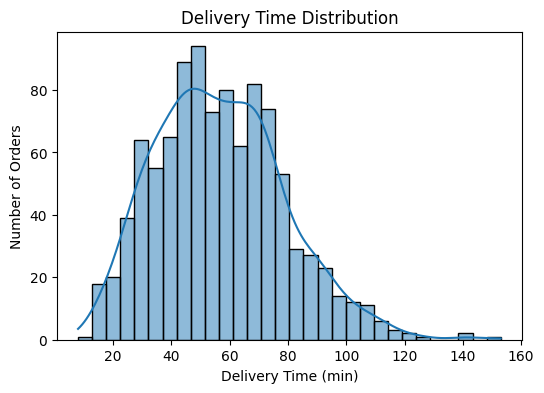

In [3]:
# 1. Histogram: distribusi target
plt.figure(figsize=(6, 4))
sns.histplot(df['Delivery_Time_min'], bins=30, kde=True)
plt.title('Delivery Time Distribution')
plt.xlabel('Delivery Time (min)')
plt.ylabel('Number of Orders')
plt.show()



Sebagian besar pesanan dikirimkan dalam kurun waktu 40-75 menitan dengan rata-rata dikisaran 50 menit. Grafiknya miring ke kanan (right-skewed). Artinya, sebagian besar pengiriman selesai tepat waktu (di bawah 80 menit), tetapi terdapat sebagian kecil pengiriman yang memakan waktu jauh lebih lama (hingga mencapai 150+ menit)

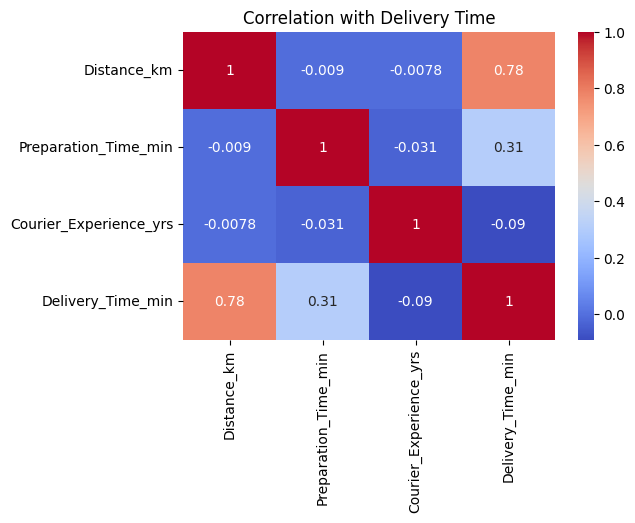

In [4]:

# 2. Heatmap: korelasi numerik
num_cols = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']
plt.figure(figsize=(6, 4))
sns.heatmap(df[num_cols + ['Delivery_Time_min']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation with Delivery Time')
plt.show()

Dari grafik heatmap dapat disimpulkan bahwa faktor utama yang mempengaruhi pengiriman adalah jarak dengan korelasi r = (0,78) dan waktu penyiapan makanan di restoran dengan korelasi=  (0,31). Sedangka pengalaman kurir memiliki korelasi paling lemah hanya (-0,09) artinya hampir tidak mempengaruhi waktu pengiriman.

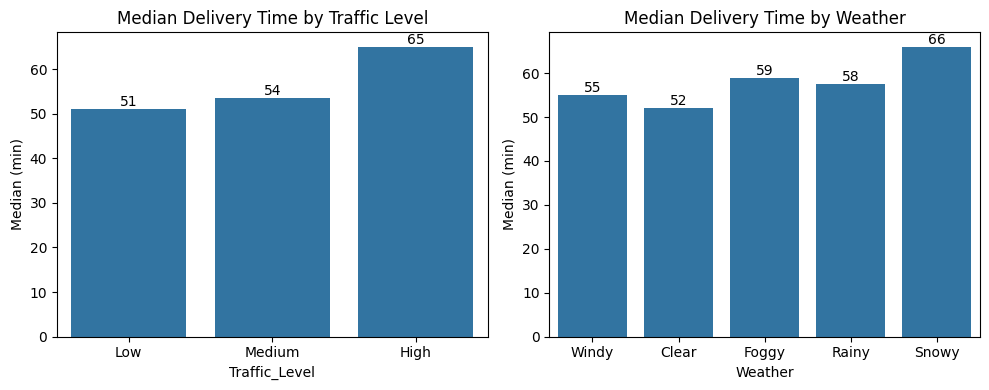

In [5]:
# 3. Median waktu antar per Traffic dan per Weather
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(data=df, x='Traffic_Level', y='Delivery_Time_min',
            order=['Low', 'Medium', 'High'],
            estimator='median', errorbar=None, ax=axes[0])
sns.barplot(data=df, x='Weather', y='Delivery_Time_min',
            estimator='median', errorbar=None, ax=axes[1])
for ax, t in zip(axes, ['Traffic Level', 'Weather']):
    ax.set_title(f'Median Delivery Time by {t}')
    ax.set_ylabel('Median (min)')
    ax.bar_label(ax.containers[0], fmt='%.0f')
plt.tight_layout()
plt.show()


Selain jarak dan waktu persiapan, faktor eksternal seperti kemacetan tinggi ($65\text{ menit}$) dan cuaca buruk/salju ($66\text{ menit}$) secara nyata meningkatkan durasi pengiriman dibanding kondisi normal ($51\text{--}52\text{ menit}$). Ini menegaskan pentingnya menambahkan buffer waktu otomatis saat kondisi lalu lintas padat atau cuaca memburuk

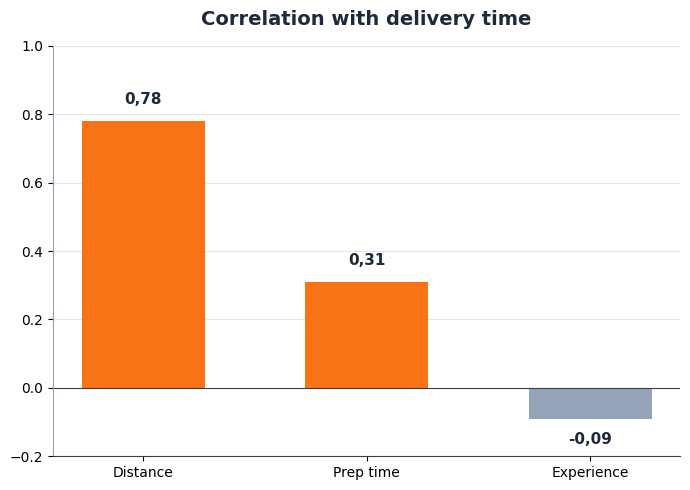

In [6]:
features = ['Distance', 'Prep time', 'Experience']
correlation_values = [0.78, 0.31, -0.09]
colors = ['#f97316' if val >= 0 else '#94a3b8' for val in correlation_values]

# Setup figure
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(features, correlation_values, color=colors, width=0.55)

# Styling sumbu & grid
ax.set_ylim(-0.2, 1.0)
ax.set_yticks([-0.2, 0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.yaxis.grid(True, linestyle='-', alpha=0.6, color='#cbd5e1')
ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#94a3b8')
ax.spines['bottom'].set_color('#334155')
ax.axhline(0, color='#334155', linewidth=0.8)

# Label nilai di atas/bawah batang
for bar, val in zip(bars, correlation_values):
    height = bar.get_height()
    text_label = f"{val:.2f}".replace('.', ',')

    if val >= 0:
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.04,
                text_label, ha='center', va='bottom', fontsize=11, fontweight='semibold', color='#1e293b')
    else:
        # Untuk nilai negatif (-0,09), posisinya ditaruh tepat di *bawah ujung bawah batang* (bukan di bawah sumbu)
        ax.text(bar.get_x() + bar.get_width()/2., height - 0.04,
                text_label, ha='center', va='top', fontsize=11, fontweight='semibold', color='#1e293b')

plt.title('Correlation with delivery time', fontsize=14, fontweight='bold', pad=15, color='#1e293b')
plt.tight_layout()
plt.show()

## 3. Split data (SEBELUM cleaning agar tidak ada data leakage)

In [7]:
X = df.drop(columns=['Delivery_Time_min', 'Order_ID'])
y = df['Delivery_Time_min']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# .copy() supaya tidak muncul SettingWithCopyWarning
X_train, X_test = X_train.copy(), X_test.copy()
print(X_train.shape, X_test.shape)

(800, 7) (200, 7)


Pada tahap pemisahan data (data splitting), dataset terlebih dahulu dibagi menjadi variabel input ($X$) dan variabel target ($y$). Kolom Delivery_Time_min dipisahkan dari variabel $X$ karena berperan sebagai target yang ingin diprediksi, sekaligus untuk mencegah terjadinya kebocoran data (data leakage). Selain itu, kolom Order_ID juga dihapus dari variabel $X$ karena merupakan identitas unik yang tidak memiliki nilai informatif untuk prediksi.   Selanjutnya, data dibagi menjadi dua bagian dengan rasio 80:20 menggunakan train_test_split, yaitu 80% sebagai data latih (train) sebanyak 800 sampel dan 20% sebagai data uji (test) sebanyak 200 sampel. Penggunaan parameter random_state=42 memastikan hasil pembagian data bersifat konsisten, sementara perintah .copy() digunakan untuk menghindari peringatan sistem saat manipulasi data berikutnya.

## 4. Cleaning: missing value (nilai pengisi dihitung dari TRAIN saja)

In [8]:
cat_missing = ['Weather', 'Traffic_Level', 'Time_of_Day']
for col in cat_missing:
    modus = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(modus)
    X_test[col] = X_test[col].fillna(modus)

median_exp = X_train['Courier_Experience_yrs'].median()
X_train['Courier_Experience_yrs'] = X_train['Courier_Experience_yrs'].fillna(median_exp)
X_test['Courier_Experience_yrs'] = X_test['Courier_Experience_yrs'].fillna(median_exp)

print("Sisa missing (train):", X_train.isnull().sum().sum())
print("Sisa missing (test) :", X_test.isnull().sum().sum())

Sisa missing (train): 0
Sisa missing (test) : 0


Pada tahap penanganan data yang hilang (missing value), pengisian nilai kosong dilakukan dengan memanfaatkan statistik yang dihitung hanya dari data latih (train) untuk mencegah terjadinya kebocoran data (data leakage). Modus untuk Kolom Kategorikal (Weather, Traffic_Level, Time_of_Day):
Alasan: Kolom-kolom ini berisi data berupa teks/kategori (bukan angka/ukuran). Median untuk Kolom Numerik (Courier_Experience_yrs): Alasan: Kolom ini berisi data angka (tahun pengalaman).

## 5. Cleaning: outlier (capping IQR, batas dari TRAIN, hanya fitur numerik)

In [9]:
for col in ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((X_train[col] < low) | (X_train[col] > high)).sum()
    print(f"{col}: {n_out} outlier di train (batas {low:.2f} - {high:.2f})")
    X_train[col] = X_train[col].clip(low, high)
    X_test[col] = X_test[col].clip(low, high)

Distance_km: 0 outlier di train (batas -9.59 - 29.66)
Preparation_Time_min: 0 outlier di train (batas -7.00 - 41.00)
Courier_Experience_yrs: 0 outlier di train (batas -5.50 - 14.50)


Pada tahap cleaning outlier, dilakukan pemeriksaan nilai pencilan pada tiga fitur numerik (Distance_km, Preparation_Time_min, dan Courier_Experience_yrs) menggunakan metode Interquartile Range (IQR) pada data train. Hasil evaluasi menunjukkan bahwa tidak terdapat nilai outlier pada ketiga fitur tersebut, karena seluruh nilai data masih berada di dalam batas toleransi wajar ($Q1 - 1.5 \times IQR$ hingga $Q3 + 1.5 \times IQR$). Dengan demikian, data dinyatakan bersih dan tidak memerlukan pemangkasan (capping), sehingga dapat langsung dilanjutkan ke tahap feature engineering

## 6. Feature engineering (HANYA dari kolom input, tidak memakai target)

In [10]:
traffic_map = {'Low': 0, 'Medium': 1, 'High': 2}

for d in (X_train, X_test):
    d['Traffic_Ord'] = d['Traffic_Level'].map(traffic_map)
    d['Dist_x_Traffic'] = d['Distance_km'] * d['Traffic_Ord']
    d['Dist_per_Exp'] = d['Distance_km'] / (d['Courier_Experience_yrs'] + 1)
    d['Bad_Weather'] = d['Weather'].isin(['Rainy', 'Snowy', 'Foggy']).astype(int)

X_train = X_train.drop(columns=['Traffic_Level'])
X_test = X_test.drop(columns=['Traffic_Level'])

Langkah ini diawali dengan mengonversi tingkat kemacetan (Traffic_Level) menjadi skala angka bertingkat (Traffic_Ord). Selanjutnya dibuat tiga fitur turunan, yaitu Dist_x_Traffic untuk mengukur beban pengiriman berdasarkan kombinasi jarak dan kemacetan, Dist_per_Exp untuk melihat rasio jarak terhadap pengalaman kurir (dengan penambahan +1 agar tidak terjadi pembagian dengan nol), serta Bad_Weather sebagai penanda biner untuk kondisi cuaca buruk. Proses diakhiri dengan menghapus kolom teks asli Traffic_Level karena nilainya sudah diwakili oleh fitur numerik baru.

## 7. Encoding kategorikal (one-hot), lalu samakan kolom test dengan train

In [11]:
X_train = pd.get_dummies(X_train, columns=['Weather', 'Time_of_Day', 'Vehicle_Type'],
                         drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=['Weather', 'Time_of_Day', 'Vehicle_Type'],
                        drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(X_train.shape, X_test.shape)
X_train.head()

(800, 16) (200, 16)


,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Traffic_Ord,Dist_x_Traffic,Dist_per_Exp,Bad_Weather,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy,Time_of_Day_Evening,Time_of_Day_Morning,Time_of_Day_Night,Vehicle_Type_Car,Vehicle_Type_Scooter
29,18.05,10,7.0,1,18.05,2.256250,0,0,0,0,0,1,0,0,0,1
535,2.14,18,3.0,2,4.28,0.535000,0,0,0,0,0,1,0,0,0,0
695,3.23,17,9.0,2,6.46,0.323000,0,0,0,0,0,0,0,0,0,0
557,7.51,27,6.0,0,0.00,1.072857,1,0,1,0,0,1,0,0,1,0
836,4.62,8,3.0,1,4.62,1.155000,1,0,1,0,0,0,0,0,1,0


Pada tahap ini, fitur bertipe kategorikal/teks (Weather, Time_of_Day, dan Vehicle_Type) diubah menjadi bentuk angka biner (0 atau 1) menggunakan teknik One-Hot Encoding (pd.get_dummies). Setelah itu, struktur kolom pada data test disesuaikan agar sama persis dengan data train untuk memastikan konsistensi fitur sebelum masuk ke tahap pemodelan.

## 8. Modeling

In [12]:
models = {
    'Baseline (rata-rata)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=200, learning_rate=0.05,
                            max_depth=3, random_state=42),
}

preds = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)

Pada tahap pemodelan, dilakukan pelatihan 4 algoritma regresi yang berbeda pada data train, yaitu Dummy Regressor (sebagai acuan dasar/baseline), Linear Regression, XGBoost, dan Random Forest. Proses ini bertujuan untuk membandingkan performa berbagai jenis algoritma dalam memprediksi durasi pengiriman

## 9. Evaluasi (MAE, RMSE, R2 pada data test)

In [13]:
rows = []
for name, y_pred in preds.items():
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred),
    })

results = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
results.round(3)

,Model,MAE,RMSE,R2
0,Linear Regression,6.052,8.940,0.822
1,XGBoost,6.657,9.559,0.796
2,Random Forest,6.795,9.605,0.794
3,Baseline (rata-rata),17.501,21.232,-0.006


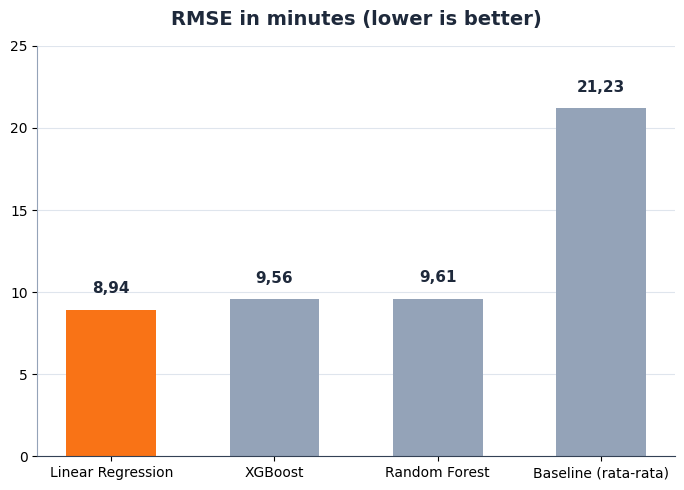

In [14]:
# Mengambil data dari DataFrame 'results' yang sudah diurutkan berdasarkan RMSE
models = results['Model']
rmse_values = results['RMSE']

# Menyoroti model terbaik (urutan pertama karena sudah di-sort ascending) dengan warna oranye, sisanya abu-abu
colors = ['#f97316' if i == 0 else '#94a3b8' for i in range(len(models))]

# Setup figure
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(models, rmse_values, color=colors, width=0.55)

# Styling sumbu & grid
ax.set_ylim(0, 25)
ax.set_yticks([0, 5, 10, 15, 20, 25])
ax.yaxis.grid(True, linestyle='-', alpha=0.6, color='#cbd5e1')
ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#94a3b8')
ax.spines['bottom'].set_color('#334155')

# Menambahkan label nilai di atas batang (format koma desimal)
for bar, val in zip(bars, rmse_values):
    height = bar.get_height()
    text_label = f"{val:.2f}".replace('.', ',')

    ax.text(bar.get_x() + bar.get_width()/2., height + 0.8,
            text_label, ha='center', va='bottom', fontsize=11, fontweight='semibold', color='#1e293b')

plt.title('RMSE in minutes (lower is better)', fontsize=14, fontweight='bold', pad=15, color='#1e293b')
plt.tight_layout()
plt.show()

Pada tahap evaluasi, performa setiap model diukur menggunakan metrik MAE, RMSE, dan $R^2$ pada data test yang diurutkan berdasarkan nilai RMSE terkecil. Hasil evaluasi menunjukkan bahwa Linear Regression menjadi model terbaik dengan tingkat eror terendah (MAE = 6.052 menit, RMSE = 8.940) serta mampu menjelaskan 82.2% variasi data ($R^2 = 0.822$). Algoritma berbasis tree seperti XGBoost ($R^2 = 0.796$) dan Random Forest ($R^2 = 0.794$) menyusul di urutan berikutnya, sementara model Baseline berkinerja paling buruk. Dengan demikian, Linear Regression dipilih sebagai model utama untuk melakukan prediksi waktu pengiriman

## 10. Interpretasi: feature importance (Random Forest)

Distance_km               17.56
Preparation_Time_min       7.03
Traffic_Ord                4.31
Bad_Weather                2.43
Courier_Experience_yrs    -2.21
Weather_Snowy              1.29
dtype: float64


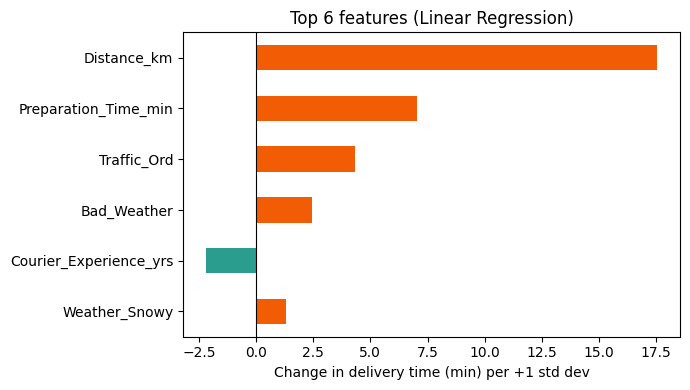

5.725900135607825


In [15]:
# Re-initialize and train Linear Regression locally to prevent overwritten variable conflicts
lr = LinearRegression()
lr.fit(X_train, y_train)

# koefisien standar: menit perubahan waktu antar per +1 std dev fitur
coef_std = pd.Series(lr.coef_ * X_train.astype(float).std().values,
                     index=X_train.columns)

top = coef_std.reindex(coef_std.abs().sort_values(ascending=False).index).head(6)
print(top.round(2))

plt.figure(figsize=(7, 4))
colors = ['#F25C05' if v > 0 else '#2A9D8F' for v in top.values[::-1]]
top[::-1].plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 6 features (Linear Regression)')
plt.xlabel('Change in delivery time (min) per +1 std dev')
plt.tight_layout()
plt.show()
print(X_train['Distance_km'].std())

Berdasarkan analisis feature importance dari model Random Forest, jarak pengiriman (Distance_km) menjadi fitur yang paling berpengaruh secara dominan terhadap durasi pengiriman, diikuti oleh waktu persiapan (Preparation_Time_min). Fitur-fitur lain seperti rasio jarak, tingkat kemacetan, dan jenis cuaca memiliki kontribusi pengaruh yang relatif lebih kecil.

## 11. Aktual vs prediksi (model terbaik)

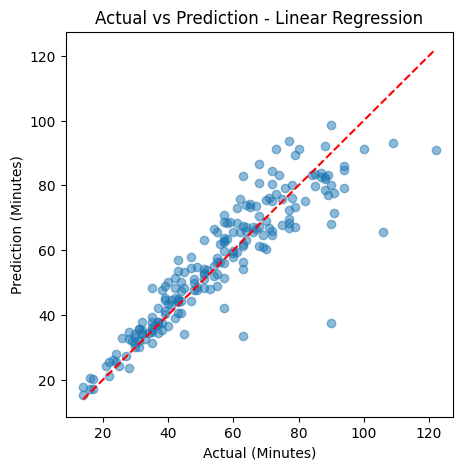

In [16]:
best_name = results.loc[0, 'Model']
y_best = preds[best_name]

plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_best, alpha=0.5)
lims = [min(y_test.min(), y_best.min()), max(y_test.max(), y_best.max())]
plt.plot(lims, lims, 'r--')
plt.xlabel('Actual (Minutes)')
plt.ylabel('Prediction (Minutes)')
plt.title(f'Actual vs Prediction - {best_name}')
plt.show()

Visualisasi grafik sebaran (scatter plot) antara nilai aktual dan hasil prediksi dari model terbaik menunjukkan titik-titik data yang menyebar mengikuti garis lurus ideal (garis merah putus-putus). Hal ini mengonfirmasi bahwa model mampu memprediksi waktu pengiriman secara cukup akurat dan konsisten sesuai pola data sebenarnya.    

## 12. Fungsi preprocessing untuk data baru

In [17]:
def preprocess_new(df_new):
    d = df_new.copy()

    d['Courier_Experience_yrs'] = d['Courier_Experience_yrs'].fillna(median_exp)

    d['Traffic_Ord'] = d['Traffic_Level'].map(traffic_map)
    d['Dist_x_Traffic'] = d['Distance_km'] * d['Traffic_Ord']
    d['Dist_per_Exp'] = d['Distance_km'] / (d['Courier_Experience_yrs'] + 1)
    d['Bad_Weather'] = d['Weather'].isin(['Rainy', 'Snowy', 'Foggy']).astype(int)
    d = d.drop(columns=['Traffic_Level'])

    d = pd.get_dummies(d, columns=['Weather', 'Time_of_Day', 'Vehicle_Type'], dtype=int)
    d = d.reindex(columns=X_train.columns, fill_value=0)
    return d

## 13. Prediksi waktu pengantaran dengan data baru (Linear Regression)

In [18]:
new_data = pd.DataFrame({
    'Distance_km':            [5.0, 12.5, 20.0],
    'Weather':                ['Clear', 'Rainy', 'Foggy'],
    'Traffic_Level':          ['Low', 'High', 'Medium'],
    'Time_of_Day':            ['Morning', 'Evening', 'Night'],
    'Vehicle_Type':           ['Bike', 'Scooter', 'Car'],
    'Preparation_Time_min':   [10, 20, 25],
    'Courier_Experience_yrs': [3.0, 1.0, 5.0],
})

X_new = preprocess_new(new_data)

# Re-initialize and retrain models to avoid the overwritten variable issue
trained_models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42)
}

for name, model in trained_models.items():
    model.fit(X_train, y_train)

best_model = trained_models['Linear Regression']
hasil = new_data.copy()
hasil['Prediksi_Waktu_min'] = best_model.predict(X_new).round(1)
hasil

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Prediksi_Waktu_min
0,5.0,Clear,Low,Morning,Bike,10,3.0,28.9
1,12.5,Rainy,High,Evening,Scooter,20,1.0,78.2
2,20.0,Foggy,Medium,Night,Car,25,5.0,98.0


In [19]:
X_full = pd.concat([X_train, X_test], axis=0)
y_full = pd.concat([y_train, y_test], axis=0)

df_final = X_full.copy()
df_final['Delivery_Time_min'] = y_full

# Export ke CSV
df_final.to_csv("cleaned_food_delivery_16features.csv", index=False)
print("Selesai. Shape akhir:", df_final.shape)

Selesai. Shape akhir: (1000, 17)
